# 05. 압하 배분 최적화 (단조 제약 GBDT + khj 최적화)

- **모델:** `ojs/force_model.py`의 GBDT (학습률 0.1, 나무 1,400개, 단조 제약)
- **최적화:** `khj/optimize.py` (김하진). 과거 운영 범위 안에서 최종 두께를 맞추는 배분 후보 3,000개를 만들고, "최대 이용률 + 0.5 × 이용률 편차"가 가장 낮은 후보를 골라요.
- **데이터:** pjh 정리 기준 (`pjh/data_utils.py`, 코일 7,533개)

순서
1. 단조 제약을 넣어도 정확도가 유지되는지 확인 (처음 보는 코일 20%로 평가)
2. 시연 코일(2744, 2599)을 물리식 / GBDT(제약 없음) / GBDT(단조 제약)로 최적화해서 비교
3. 표본 코일 200개로 전체 효과 요약

## 0. 준비

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import r2_score, mean_absolute_error

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "khj/optimize.py").exists())
sys.dont_write_bytecode = True   # 다른 팀원 폴더에 캐시를 만들지 않음
for sub in ["ojs", "khj"]:
    sys.path.insert(0, str(REPO / sub))
from force_model import train, make_predict_fn, features
from optimize import load_data, limits_from_data, coil_from_data, optimize, physics_predictor

df = load_data()                 # pjh 정리 데이터 + 파생 변수
lim = limits_from_data(df)       # 압하율 범위(1~99%), 이용률 기준 하중(상위 0.5%)
print(f"{len(df):,}행, 코일 {df['Coil ID'].nunique():,}개")
print("이용률 기준 하중 (MN):", dict(zip(["F1", "F2", "F3", "F4", "F5"], lim.cap.round(1))))

37,665행, 코일 7,533개
이용률 기준 하중 (MN): {'F1': np.float64(36.4), 'F2': np.float64(33.7), 'F3': np.float64(23.6), 'F4': np.float64(19.4), 'F5': np.float64(14.3)}


## 1. 단조 제약을 넣어도 정확한가?

pjh 기준 모델과 같은 방식(`GroupShuffleSplit`, 코일 20%, `random_state=42`)으로 처음 보는 코일을 떼어 평가해요.
**더 누르면 하중 감소 (%)** 는 각 행의 출측 두께를 압하량의 5%만큼 더 얇게 했을 때 예측 하중이 줄어든 행의 비율이에요(물리적으로는 0%여야 함).

In [2]:
tr_idx, te_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42).split(df, groups=df["Coil ID"]))
train_df, test_df = df.iloc[tr_idx], df.iloc[te_idx]

more = test_df.copy()
more["Exit gauge (mm)"] = test_df["Exit gauge (mm)"] - 0.05 * (test_df["Entry gauge (mm)"] - test_df["Exit gauge (mm)"])

rows = []
for name, mono in [("GBDT (제약 없음)", False), ("GBDT (단조 제약)", True)]:
    start = time.time()
    m = train(train_df, monotonic=mono)
    p = m.predict(features(test_df))
    p_more = m.predict(features(more))
    y = test_df["force_MN"]
    rows.append({"모델": name, "R²": r2_score(y, p), "MAE (MN)": mean_absolute_error(y, p),
                 "평균 오차율 (%)": ((p - y).abs() / y).mean() * 100,
                 "더 누르면 하중 감소 (%)": (p_more < p - 1e-9).mean() * 100,
                 "학습 시간 (초)": time.time() - start})
mono_table = pd.DataFrame(rows).set_index("모델")
display(mono_table.style.format({"R²": "{:.4f}", "MAE (MN)": "{:.3f}", "평균 오차율 (%)": "{:.2f}",
                                 "더 누르면 하중 감소 (%)": "{:.1f}", "학습 시간 (초)": "{:.0f}"}))

,R²,MAE (MN),평균 오차율 (%),더 누르면 하중 감소 (%),학습 시간 (초)
모델,,,,,
GBDT (제약 없음),0.9927,0.415,2.31,7.4,9
GBDT (단조 제약),0.9918,0.444,2.47,0.0,9


- 단조 제약을 넣으니 **"더 누르면 하중 감소"가 7.4% → 0%** 가 됐어요.
- 정확도는 조금만 내려가요: MAE 0.415 → 0.444 MN, R² 0.9927 → 0.9918.
- → 최적화·시뮬레이터에는 **단조 제약 모델**을 써요. 0.03 MN을 내주고 물리적으로 말이 되는 모델을 얻었어요.

### 같은 평가 데이터로 물리식·MLP까지 한 표로 (발표용)

팀 발표 표를 하나로 맞추려고, 위와 같은 코일 20%로 물리식(M3)과 MLP도 평가해요. MLP는 02와 같은 구조예요(128 → 64, 에폭 60).

,R²,MAE (MN),평균 오차율 (%)
물리식 M3 (기준선),0.946,1.24,7.2
MLP,0.988,0.56,3.2
GBDT (단조 제약),0.992,0.44,2.5


스탠드별 R²


Stand ID,F1,F2,F3,F4,F5
물리식 M3 (기준선),0.82,0.80,0.79,0.80,0.38
MLP,0.96,0.96,0.95,0.95,0.91
GBDT (단조 제약),0.97,0.97,0.97,0.96,0.94


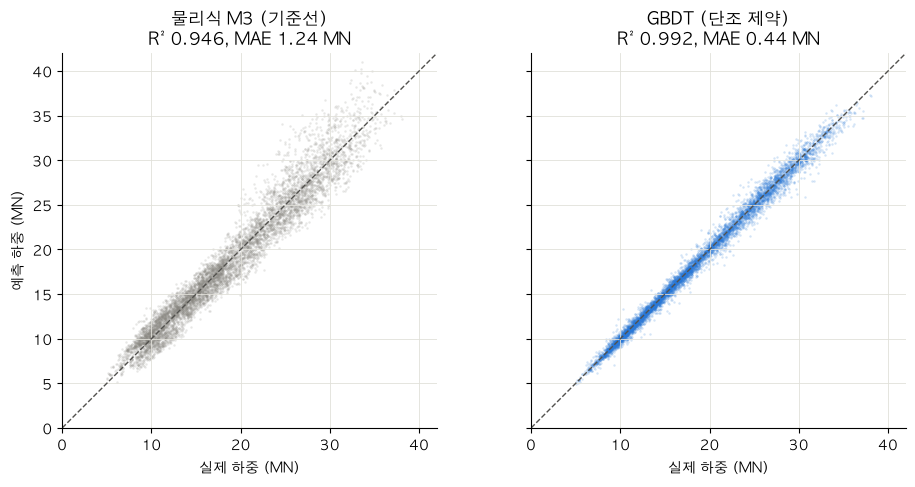

In [3]:
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset
import matplotlib.pyplot as plt
from matplotlib import font_manager

y_test = test_df["force_MN"]
preds = {"물리식 M3 (기준선)": physics_predictor(train_df)(test_df)}

# MLP (02와 같은 구조)
torch.set_num_threads(1)
torch.manual_seed(0)
Xtr_df, Xte_df = features(train_df), features(test_df)
num = [c for c in Xtr_df.columns if c != "grade"]
mu, sd = Xtr_df[num].mean(), Xtr_df[num].std()
def to_t(X):
    oh = pd.get_dummies(X["grade"]).astype(float)
    return torch.tensor(np.hstack([((X[num] - mu) / sd).to_numpy(), oh.to_numpy()]), dtype=torch.float32)
ym, ys = train_df["force_MN"].mean(), train_df["force_MN"].std()
net = nn.Sequential(nn.Linear(len(num) + 10, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 1))
opt = torch.optim.Adam(net.parameters(), lr=1e-3)
sch = torch.optim.lr_scheduler.CosineAnnealingLR(opt, 60)
loader = DataLoader(TensorDataset(to_t(Xtr_df), torch.tensor(((train_df["force_MN"] - ym) / ys).to_numpy(), dtype=torch.float32)),
                    batch_size=256, shuffle=True, generator=torch.Generator().manual_seed(0))
for _ in range(60):
    for xb, yb in loader:
        opt.zero_grad(); nn.functional.mse_loss(net(xb).squeeze(1), yb).backward(); opt.step()
    sch.step()
with torch.no_grad():
    preds["MLP"] = net(to_t(Xte_df)).squeeze(1).numpy() * ys + ym
preds["GBDT (단조 제약)"] = p   # 위 칸에서 마지막으로 학습한 단조 제약 모델의 예측

team_table = pd.DataFrame({k: {"R²": r2_score(y_test, v), "MAE (MN)": mean_absolute_error(y_test, v),
                               "평균 오차율 (%)": (np.abs(np.asarray(v) - y_test) / y_test).mean() * 100}
                           for k, v in preds.items()}).T
stand_r2 = pd.DataFrame({k: pd.Series(np.asarray(v), index=test_df.index).groupby(test_df["Stand ID"]).apply(
    lambda s: r2_score(y_test[s.index], s)) for k, v in preds.items()}).T
display(team_table.style.format({"R²": "{:.3f}", "MAE (MN)": "{:.2f}", "평균 오차율 (%)": "{:.1f}"}))
print("스탠드별 R²")
display(stand_r2.round(2))

# 실제-예측 산점도 (발표용, ojs/figures/에 저장)
installed = {f.name for f in font_manager.fontManager.ttflist}
for font in ["AppleGothic", "Malgun Gothic", "NanumGothic"]:
    if font in installed:
        plt.rcParams["font.family"] = font
        break
plt.rcParams["axes.unicode_minus"] = False
fig, axes = plt.subplots(1, 2, figsize=(10, 4.8), sharex=True, sharey=True)
for ax, name, color in zip(axes, ["물리식 M3 (기준선)", "GBDT (단조 제약)"], ["#898781", "#2a78d6"]):
    v = np.asarray(preds[name])
    ax.scatter(y_test, v, s=3, alpha=0.2, color=color, linewidths=0)
    ax.plot([0, 42], [0, 42], color="#52514e", linewidth=1, linestyle="--")
    ax.set_xlim(0, 42); ax.set_ylim(0, 42); ax.set_aspect("equal")
    ax.set_title(f"{name}\nR² {r2_score(y_test, v):.3f}, MAE {mean_absolute_error(y_test, v):.2f} MN")
    ax.set_xlabel("실제 하중 (MN)")
    ax.grid(color="#e1e0d9", linewidth=0.6)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("예측 하중 (MN)")
plt.tight_layout()
(REPO / "ojs/figures").mkdir(exist_ok=True)
fig.savefig(REPO / "ojs/figures/actual_vs_pred.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. 최종 모델 학습과 시연 코일 최적화

시뮬레이터에 들어갈 모델은 정리 데이터 전체로 학습해요. 같은 코일을 모델 3개로 최적화해서 비교해요.

In [4]:
start = time.time()
models = {
    "물리식 M3": physics_predictor(df),
    "GBDT (제약 없음)": make_predict_fn(train(df, monotonic=False)),
    "GBDT (단조 제약)": make_predict_fn(train(df, monotonic=True)),
}
print(f"학습 {time.time() - start:.0f}초")

def show(coil_id):
    coil = coil_from_data(coil_id, df)
    actual = df[df["Coil ID"] == coil_id].sort_values("Stand ID")["force_MN"].to_numpy()
    print(f"\n코일 {coil_id}: {coil.grade}, 폭 {coil.width:.0f} mm, {coil.h0:.2f} → {coil.h_final:.2f} mm")
    out = []
    for name, fn in models.items():
        res = optimize(coil, fn, lim)
        cur, best = res["current"], res["best"]
        out.append({"모델": name,
                     "현재 예측 하중 (MN)": " / ".join(f"{v:.1f}" for v in cur["forces_MN"]),
                     "추천 하중 (MN)": " / ".join(f"{v:.1f}" for v in best["forces_MN"]),
                     "추천 압하율": " / ".join(f"{v:.2f}" for v in best["reductions"]),
                     "최대 이용률 현재→추천": f"{cur['util'].max():.3f} → {best['util'].max():.3f}",
                     "감소율 (%)": round(res["util_max_drop_pct"], 1),
                     "최대 하중 현재→추천": f"{cur['forces_MN'].max():.1f} → {best['forces_MN'].max():.1f}",
                     "병목": f"{cur['bottleneck']} → {best['bottleneck']}"})
    print("실측 하중 (MN):", " / ".join(f"{v:.1f}" for v in actual),
          "| 현재 압하율:", " / ".join(f"{v:.2f}" for v in coil.reductions))
    display(pd.DataFrame(out).set_index("모델"))

for coil_id in [2744, 2599]:
    show(coil_id)

학습 20초

코일 2744: Grade02, 폭 1235 mm, 31.95 → 6.44 mm
실측 하중 (MN): 26.8 / 16.5 / 12.5 / 9.9 / 7.5 | 현재 압하율: 0.45 / 0.30 / 0.26 / 0.19 / 0.14


,현재 예측 하중 (MN),추천 하중 (MN),추천 압하율,최대 이용률 현재→추천,감소율 (%),최대 하중 현재→추천,병목
모델,,,,,,,
물리식 M3,23.9 / 16.3 / 13.3 / 10.3 / 7.7,21.3 / 18.2 / 13.2 / 11.0 / 8.1,0.40 / 0.34 / 0.26 / 0.20 / 0.14,0.656 → 0.584,11.0,23.9 → 21.3,F1 → F1
GBDT (제약 없음),26.7 / 16.0 / 12.8 / 10.0 / 7.9,21.0 / 20.2 / 13.6 / 11.5 / 8.7,0.34 / 0.36 / 0.27 / 0.22 / 0.16,0.733 → 0.609,16.9,26.7 → 21.0,F1 → F5
GBDT (단조 제약),27.1 / 15.5 / 13.1 / 10.0 / 8.0,20.8 / 20.3 / 13.8 / 11.3 / 8.7,0.34 / 0.36 / 0.27 / 0.22 / 0.16,0.744 → 0.606,18.5,27.1 → 20.8,F1 → F5



코일 2599: Grade02, 폭 1578 mm, 30.23 → 3.95 mm
실측 하중 (MN): 35.7 / 24.4 / 17.7 / 16.0 / 10.1 | 현재 압하율: 0.54 / 0.38 / 0.30 / 0.23 / 0.16


,현재 예측 하중 (MN),추천 하중 (MN),추천 압하율,최대 이용률 현재→추천,감소율 (%),최대 하중 현재→추천,병목
모델,,,,,,,
물리식 M3,37.4 / 25.6 / 18.7 / 15.0 / 10.7,31.2 / 27.4 / 20.7 / 16.3 / 12.3,0.46 / 0.41 / 0.33 / 0.25 / 0.19,1.026 → 0.878,14.4,37.4 → 31.2,F1 → F3
GBDT (제약 없음),35.7 / 24.4 / 17.7 / 15.5 / 10.3,30.1 / 29.2 / 20.1 / 15.8 / 11.5,0.43 / 0.44 / 0.35 / 0.23 / 0.17,0.979 → 0.868,11.3,35.7 → 30.1,F1 → F2
GBDT (단조 제약),35.5 / 24.3 / 17.1 / 15.0 / 10.4,29.7 / 28.7 / 19.7 / 15.6 / 12.3,0.42 / 0.43 / 0.35 / 0.24 / 0.20,0.976 → 0.862,11.7,35.5 → 29.7,F1 → F5


- **코일 2744 (메인 시연):** 단조 제약 GBDT로 F1 병목이 풀려 최대 이용률 0.744 → 0.606(**−18.5%**), 최대 하중 27.1 → 20.8 MN이에요. F1 압하율을 0.45 → 0.34로 줄이고 F2를 0.30 → 0.36으로 늘리는 배분이에요.
- **코일 2599 (보조 시연):** F1 이용률 0.976(한계 직전) → 0.862(**−11.7%**), 최대 하중 35.5 → 29.7 MN이에요.
- GBDT가 현재 배분의 실측 하중을 잘 맞혀요(2744 F1 실측 26.8 vs 예측 27.1 MN). 물리식은 F1을 23.9로 낮게 봐서, F1 병목을 덜 심각하게 판단해요.
- 제약 없는 GBDT와 추천 배분은 거의 같아요. 시연 코일에서는 제약 때문에 결과가 달라지지 않았어요.

## 3. 표본 코일 200개로 전체 효과 요약

코일 7,533개를 모두 돌리면 오래 걸려서, 무작위 200개로 요약해요(한 코일에 후보 3,000개 × 5스탠드를 예측).

In [5]:
sample_ids = df["Coil ID"].drop_duplicates().sample(200, random_state=0).tolist()
summary = {}
start = time.time()
for name in ["물리식 M3", "GBDT (단조 제약)"]:
    rows, skipped = [], 0
    for cid in sample_ids:
        try:
            res = optimize(coil_from_data(cid, df), models[name], lim)
        except ValueError:      # 과거 운영 범위 안에서 목표 두께를 맞출 수 없는 코일
            skipped += 1
            continue
        rows.append({"util_drop": res["util_max_drop_pct"],
                     "force_drop": (1 - res["best"]["forces_MN"].max() / res["current"]["forces_MN"].max()) * 100})
    r = pd.DataFrame(rows)
    summary[name] = {"최대 이용률 감소 중앙값 (%)": r["util_drop"].median(),
                     "최대 이용률 감소 평균 (%)": r["util_drop"].mean(),
                     "5% 이상 줄어든 코일 (%)": (r["util_drop"] >= 5).mean() * 100,
                     "최대 감소 (%)": r["util_drop"].max(),
                     "최대 하중(MN)이 늘어난 코일 (%)": (r["force_drop"] < 0).mean() * 100,
                     "건너뛴 코일 (범위 밖)": skipped}
print(f"{time.time() - start:.0f}초")
display(pd.DataFrame(summary).T.round(1))

31초


,최대 이용률 감소 중앙값 (%),최대 이용률 감소 평균 (%),5% 이상 줄어든 코일 (%),최대 감소 (%),최대 하중(MN)이 늘어난 코일 (%),건너뛴 코일 (범위 밖)
물리식 M3,2.3,3.5,25.5,18.9,67.3,4.0
GBDT (단조 제약),1.0,1.8,11.2,16.3,51.0,4.0


- **효과는 일부 코일에 몰려 있어요.** 단조 제약 GBDT 기준으로 최대 이용률 감소는 중앙값 1.0%, 평균 1.8%예요. 하지만 11.2%의 코일은 5% 넘게, 많게는 16.3%까지 줄어요. 현장이 평균적으로는 이미 균형을 맞추고 있고, **치우친 코일을 찾아 고치는 게 이 시스템의 쓸모**예요.
- **물리식은 효과를 부풀려요.** 같은 최적화를 물리식으로 하면 5% 이상 개선이 25.5%로 두 배 넘게 나와요. 물리식은 압하에 따른 하중 변화를 실제보다 크게 보기 때문이에요(02 노트북 8번: 압하 5% 증가 시 물리식 +0.87 MN, AI +0.6 MN). 그래서 추천은 더 정확한 GBDT로 해야 해요.
- **⚠️ 이용률이 줄어도 최대 하중(MN)은 늘 수 있어요.** 51% 코일에서 추천 후 최대 하중이 늘었어요. 점수가 "스탠드별 과거 최대 하중 대비 비율(이용률)"이라서, 기준 하중이 큰 F1·F2로 하중을 옮기기 때문이에요. 화면과 발표에서 **이용률과 MN을 항상 같이** 보여 주고, 시연은 최대 하중도 같이 줄어드는 코일(2744, 2599)로 해요.
- 4%의 코일은 과거 운영 범위 안에서 목표 두께를 맞출 수 없어서 추천하지 않아요(범위 밖 조건 → "신뢰도 낮음").